In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.cluster import KMeans

## 請安裝
> pip install opencv-python

# Problem : K-Means Clustering
**K-Means Clustering** is an unsupervised learning algorithm for data grouping. In image segmen- tation, it can be applied to partition image pixels into different groups based on the associated pixel values or features. In this problem, you will learn how to segment the provided image by using K-means clustering.

In [3]:
img = cv2.imread('data/bird.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

## 1-1. cluster with only RGB values

In [9]:
def km_clust(array, n_clusters):   
    # Define the k-means clustering problem
    k_m = KMeans(n_clusters = n_clusters)
    # Solve the k-means clustering problem
    k_m.fit(array)
    # Get the coordinates of the clusters centres
    center = k_m.cluster_centers_
    # Get the label of each point
    label = k_m.labels_
    return(label, center)

In [13]:
h,w,c=img.shape
print(img.shape)
Z=img.reshape((-1,3))
Z.shape
K=2
label, center=km_clust(Z,K)

(1024, 1024, 3)


In [15]:
label, center#因為Center非整數，不符合RGB的規則，需要調整

(array([1, 1, 1, ..., 1, 1, 1], shape=(1048576,), dtype=int32),
 array([[185.40047183, 187.6878428 , 166.60486368],
        [152.27372466, 182.96115036, 108.11943674]]))

In [17]:
center=np.uint8(center[:,:3])
center

array([[185, 187, 166],
       [152, 182, 108]], dtype=uint8)

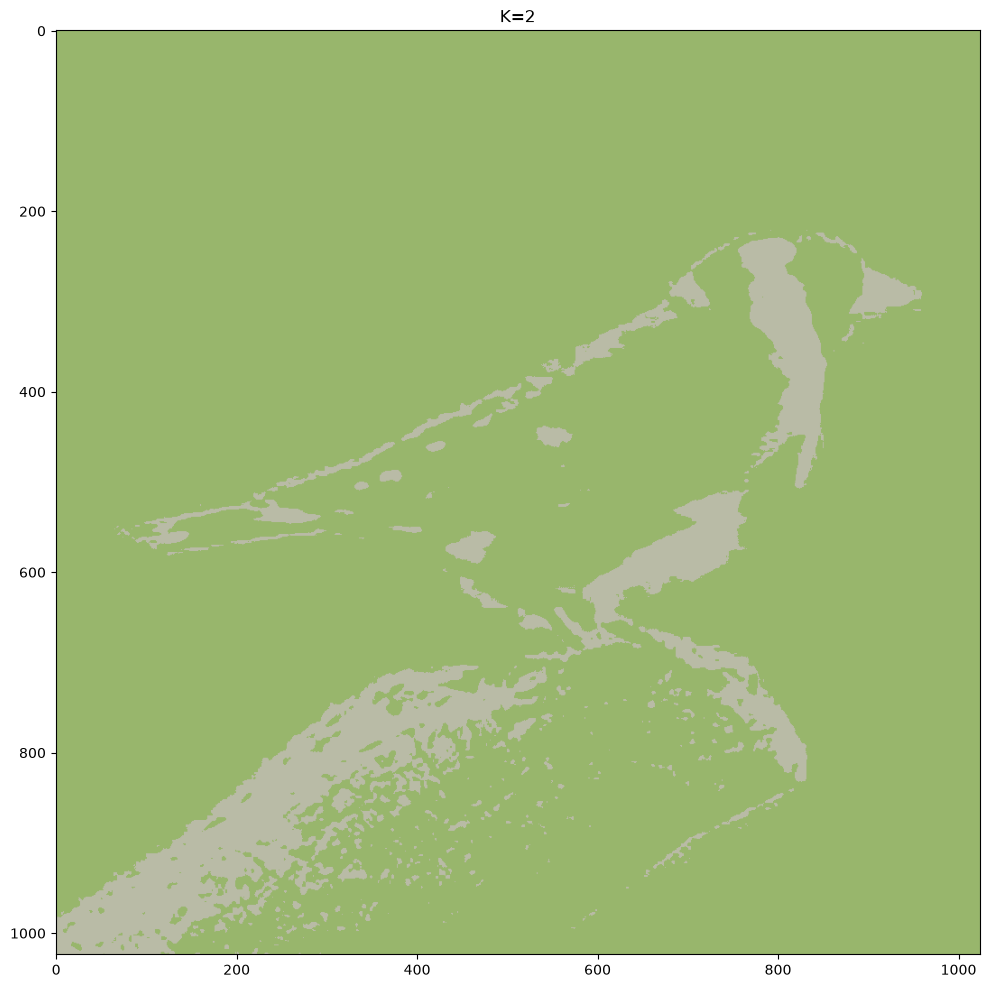

In [19]:
res=center[label.flatten()]
res=res.reshape(img.shape)
plt.figure(figsize=(16,12))
plt.title("K={}".format(K))
plt.imshow(res)

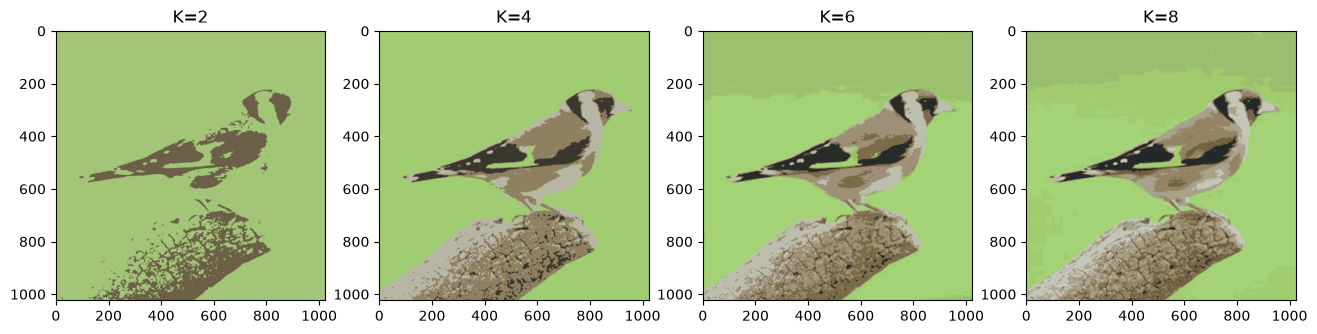

In [23]:
h,w,c=img.shape
#print(img.shape)
Z=img.reshape((-1,3))
#Z.shape
Ka=[2,4,6,8]
plt.figure(figsize=(16,12))
label, center=km_clust(Z,K)

for i,K in enumerate(Ka):
    label, center=km_clust(Z,K)
    center=np.uint8(center[:,:3])
    res=center[label.flatten()]
    res=res.reshape(img.shape)
    plt.subplot(1,len(Ka),i+1)
    plt.title("K={}".format(K))
    plt.imshow(res)

## 1-2. cluster with RGB values and the location

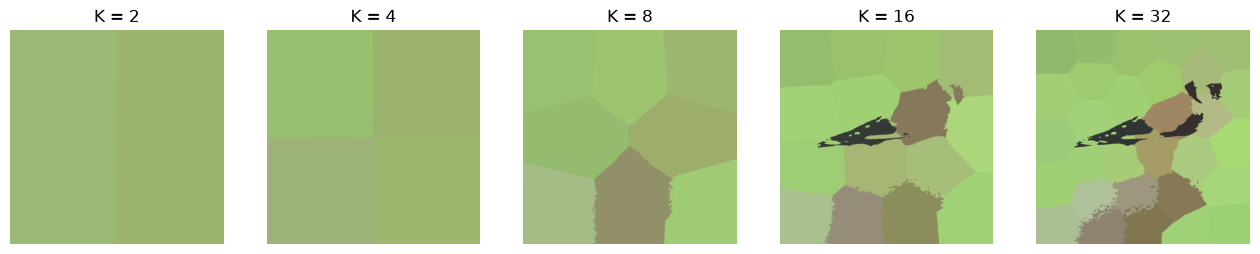

In [27]:
h, w, c = img.shape

#Added location feature
Z = np.zeros((h, w, c+2))
for h in range(len(img)):
    for w in range(len(img[h])):
        Z[h][w] = np.append(img[h][w], [[h], [w]])
Z = Z.reshape(-1, 5)

Ks = [2,4,8,16,32]
plt.figure(figsize=(16,12))

for i, K in enumerate(Ks):
    label, center = km_clust(Z, K)

    # Now convert back into uint8, and make original image
    center = np.uint8(center[:, :3])
    res = center[label.flatten()]
    res = res.reshape((img.shape))

    plt.subplot(1, 5, i+1)
    plt.axis('off')
    plt.title("K = {}".format(K))
    plt.imshow(res)
    
plt.show()

## 1-3. explain the differences between the two methods under the same K.
![](images/7.4_result.PNG)

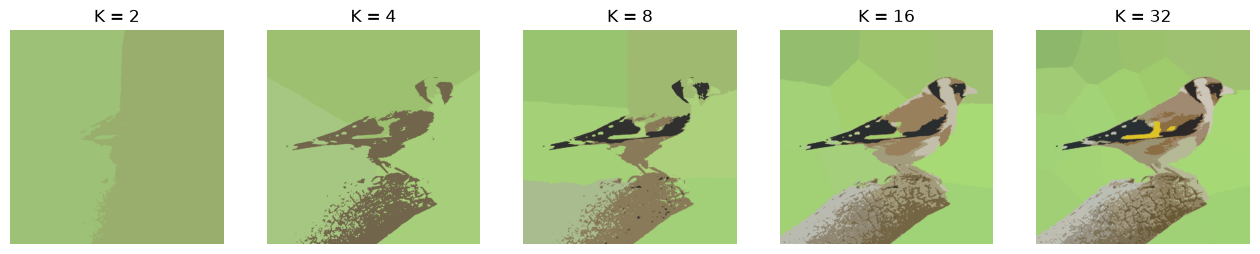

In [31]:
#因為像素是1024*1024，和RGB的比例差太多，所以採用正規化，將 [h/4], [w/4]
h, w, c = img.shape

#Added location feature
Z = np.zeros((h, w, c+2))
for h in range(len(img)):
    for w in range(len(img[h])):
        Z[h][w] = np.append(img[h][w], [[h/4], [w/4]])
Z = Z.reshape(-1, 5)

Ks = [2,4,8,16,32]
plt.figure(figsize=(16,12))

for i, K in enumerate(Ks):
    label, center = km_clust(Z, K)

    # Now convert back into uint8, and make original image
    center = np.uint8(center[:, :3])
    res = center[label.flatten()]
    res = res.reshape((img.shape))

    plt.subplot(1, 5, i+1)
    plt.axis('off')
    plt.title("K = {}".format(K))
    plt.imshow(res)
    
plt.show()